# Personas ocupadas en carencia material y social severa

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "carencia-material-ocupados"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Personas ocupadas en carencia material y social severa"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de las personas ocupadas de 18 años o más"
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de las personas ocupadas de 18 años o más (según su situación laboral más frecuente del año anterior) que no pueden permitirse al menos 7 de 13 gastos básicos: 7 del hogar (pagar a tiempo el alquiler, la hipoteca o los recibos; mantener la vivienda a una temperatura adecuada; afrontar un gasto imprevisto; comer carne, pollo o pescado al menos cada dos días; una semana de vacaciones al año fuera de casa; un coche; sustituir muebles estropeados) y 6 personales (sustituir ropa estropeada, dos pares de zapatos, reunirse con amigos o familia una vez al mes, una actividad de ocio, gastar una pequeña cantidad en sí mismo y conexión a internet). Es la *tasa de carencia material y social severa* de la UE, uno de los tres componentes de la tasa de riesgo de pobreza o exclusión social (AROPE).

**Por qué este indicador y no la tasa de riesgo de pobreza de quienes trabajan.** La tasa de riesgo de pobreza cuenta a quienes tienen una renta inferior al 60 % de la mediana de su país: mide su renta frente a la del resto de la población. La carencia material no depende de la mediana: pregunta directamente qué puede permitirse el hogar. Es el eje vertical de la dispersión `smi-pobreza-laboral`; aquí se ve su evolución (por indicación humana del 2026-10-22).

**Limitaciones.**
- La carencia se mide en todo el hogar: depende del salario de la persona ocupada, pero también de los demás ingresos y del tamaño del hogar.
- Eurostat publica este indicador desde 2015. El indicador anterior de carencia material severa (9 conceptos, solo del hogar) no es comparable y no se enlaza.
- Se basa en lo que declaran los hogares en la encuesta EU-SILC; lo que significa no poder permitirse cada gasto cambia con el clima, los precios y las costumbres de cada país.
- Solo existe para los países de la encuesta europea: Estados Unidos, Canadá y la OCDE quedan sin dato.

## 2. Descarga

- **España y UE-27:** Eurostat, EU-SILC, tasa de carencia material y social severa por situación laboral más frecuente (`ilc_mdsd12`), personas ocupadas (`EMP`) de 18 años o más (`Y_GE18`), ambos sexos, en %.
- **Comprobación (no se publica como serie):** la tasa de riesgo de pobreza de las personas ocupadas (`ilc_iw01`, `EMP`, `Y_GE18`), para ver en las notas cómo se comparan los dos indicadores.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from lib import eurostat
from lib.tipos import FuenteMeta

eu, fuentes_eu = eurostat.get("ilc_mdsd12", {"freq": "A", "wstatus": "EMP", "unit": "PC", "sex": "T", "age": "Y_GE18"}, desde=DESDE)
arop, _ = eurostat.get("ilc_iw01", {"freq": "A", "wstatus": "EMP", "unit": "PC", "sex": "T", "age": "Y_GE18"}, desde=DESDE)
eu.pivot(index="periodo", columns="serie", values="valor")

serie,espana,ue27
periodo,,
2015,3.3,5.5
2016,4.1,5.0
2017,3.9,4.3
2018,3.7,3.8
2019,3.4,3.5
2020,5.3,3.7
2021,4.5,3.3
2022,4.9,3.8
2023,6.5,4.1


## 3. Transformación

Sin transformación: Eurostat publica el porcentaje. Estados Unidos, Canadá y la OCDE quedan en `null` (no hay encuesta EU-SILC).

In [ ]:
def fmt(x, decimales=1):
    return estilos.formato_es(x, decimales).replace("-", "−")


serie = lambda d, s: d[d["serie"] == s].set_index("periodo")["valor"]
HOY = fuentes_eu[0].fecha_consulta
fuentes = [FuenteMeta(f.serie, f.organismo, "ilc_mdsd12 (wstatus=EMP, age=Y_GE18, sex=T, unit=PC)", f.url, f.fecha_consulta) for f in fuentes_eu]
SIN = {
    "ocde": "sin media de la OCDE: el indicador solo existe en la encuesta europea EU-SILC",
    "eeuu": "sin dato: el indicador solo existe en la encuesta europea EU-SILC",
    "canada": "sin dato: el indicador solo existe en la encuesta europea EU-SILC",
}
df = pd.concat([eu, pd.DataFrame({"serie": list(SIN), "periodo": DESDE, "valor": float("nan")})], ignore_index=True)
fuentes += [FuenteMeta(s, eurostat.ORGANISMO, f"ilc_mdsd12: {t}", eurostat.URL_DATABROWSER.format(dataset="ilc_mdsd12"), HOY)
            for s, t in SIN.items()]

es, ar = serie(eu, "espana"), serie(arop, "espana")
ULT = int(es.index.max())
CAR_ULT, AR_ULT = float(es.loc[ULT]), float(ar.get(ULT, float("nan")))
assert pd.notna(AR_ULT), "sin tasa de riesgo de pobreza del último año"
NOTAS = [
    "España y UE-27: Eurostat, EU-SILC, tasa de carencia material y social severa (ilc_mdsd12) de las personas "
    "ocupadas de 18 años o más (situación laboral más frecuente del año anterior): no pueden permitirse al menos 7 de "
    "13 gastos básicos del hogar o personales. Media UE-27: agregado "
    "de composición actual (EU27_2020).",
    "Eurostat publica el indicador desde 2015. El indicador anterior de carencia material severa (9 conceptos) no es "
    "comparable y no se enlaza.",
    f"A diferencia de la tasa de riesgo de pobreza, que cuenta a quienes tienen una renta inferior al 60 % de la "
    f"mediana del país, no depende de la renta del resto de la población. En España, en {ULT}, el {fmt(CAR_ULT)} % "
    f"de las personas ocupadas de 18 años o más estaba en carencia material y social severa y el {fmt(AR_ULT)} % en "
    f"riesgo de pobreza (ilc_iw01).",
    "La carencia se mide en todo el hogar: depende del salario de la persona ocupada, pero también de los demás "
    "ingresos y del tamaño del hogar.",
    "OCDE, EE. UU. y Canadá: sin dato. El indicador solo existe para los países de la encuesta europea EU-SILC.",
]
for n in NOTAS:
    print("-", n)

- España y UE-27: Eurostat, EU-SILC, tasa de carencia material y social severa (ilc_mdsd12) de las personas ocupadas de 18 años o más (situación laboral más frecuente del año anterior): no pueden permitirse al menos 7 de 13 gastos básicos del hogar o personales. Media UE-27: agregado de composición actual (EU27_2020).
- Eurostat publica el indicador desde 2015. El indicador anterior de carencia material severa (9 conceptos) no es comparable y no se enlaza.
- A diferencia de la tasa de riesgo de pobreza, que cuenta a quienes tienen una renta inferior al 60 % de la mediana del país, no depende de la renta del resto de la población. En España, en 2025, el 6,4 % de las personas ocupadas de 18 años o más estaba en carencia material y social severa y el 11,2 % en riesgo de pobreza (ilc_iw01).
- La carencia se mide en todo el hogar: depende del salario de la persona ocupada, pero también de los demás ingresos y del tamaño del hogar.
- OCDE, EE. UU. y Canadá: sin dato. El indicador solo existe

## 4. Visualización

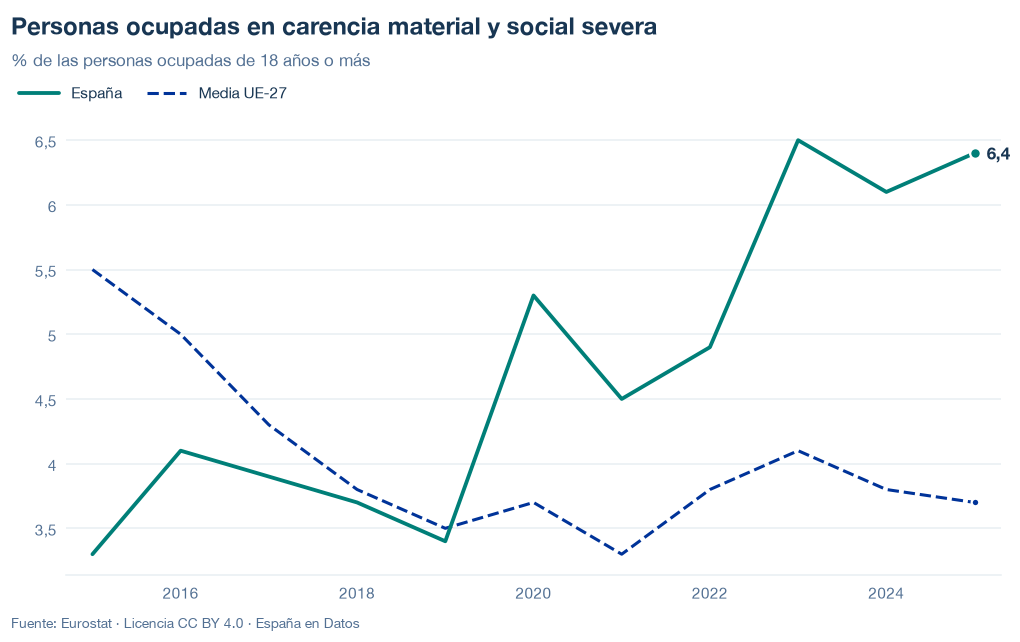

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/carencia-material-ocupados.json y data/carencia-material-ocupados.csv


## 6. Fuentes, notas y licencia

- Eurostat, EU-SILC: `ilc_mdsd12` (`EMP`, `Y_GE18`, `sex=T`, `PC`), serie de la gráfica; `ilc_iw01` (`EMP`, `Y_GE18`) para las notas.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.